In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pymongo import MongoClient

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# połączenie z MongoDB
client = MongoClient("mongodb://localhost:27017/")
db = client["kpop_db"]
collection_awards = db["kpop_music_show_awards_2006_2026"]

# pobieranie danych do dataframe
data_awards = list(collection_awards.find({}, {"_id": 0}))
df_awards = pd.DataFrame(data_awards)

df_awards.columns = df_awards.columns.str.replace('\ufeff', '').str.strip()

print(f"pomyślnie wczytano {len(df_awards)} rekordów nagród muzycznych ^^")
display(df_awards.head(3))

pomyślnie wczytano 8918 rekordów nagród muzycznych ^^


,year,period,award_name,artist,song,artist_id
0,2006,2006 5112-18 do 12-24,M Countdown,NaN,NaN,NaN
1,2006,2006 5112-18 do 12-24,Inkigayo,Woohyuk,One Way,8245.0
2,2006,2006 5012-11 do 12-17,M Countdown,NaN,NaN,NaN


In [2]:
# usuwanie 'pustych' rekordów
df_awards = df_awards.dropna(subset=['artist', 'song'])

print(f"liczba rekordów po usunięciu pustych wpisów = {len(df_awards)}")
display(df_awards.head(3))

liczba rekordów po usunięciu pustych wpisów = 8632


,year,period,award_name,artist,song,artist_id
1,2006,2006 5112-18 do 12-24,Inkigayo,Woohyuk,One Way,8245.0
3,2006,2006 5012-11 do 12-17,Inkigayo,Junjin,Love Doesn't Come,3861.0
5,2006,2006 4912-04 do 12-10,Inkigayo,Se7en,La La La,6676.0



najwięcej wygranych nagród


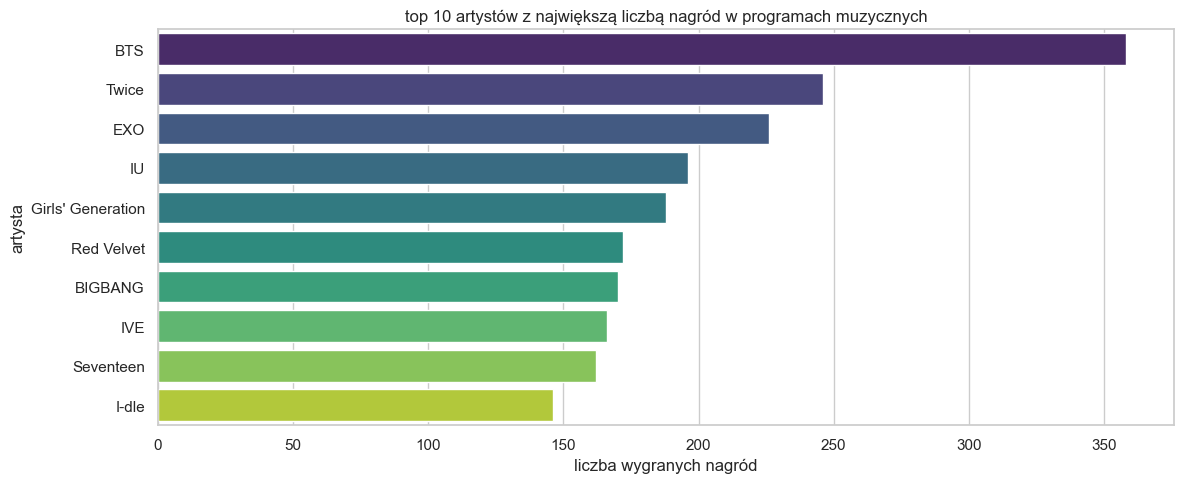

rozkład nagród według stacji/programów muzycznych


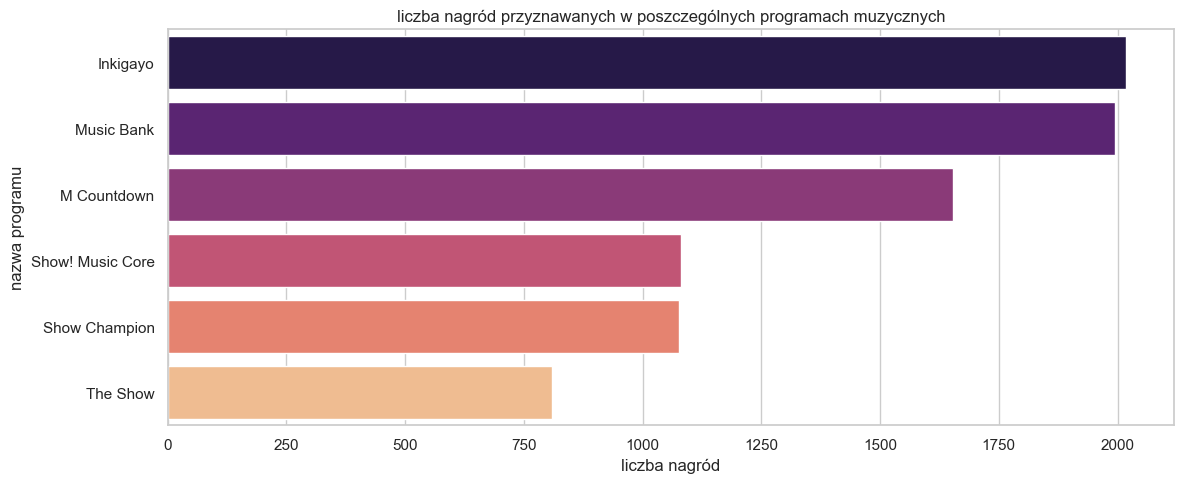

dynamika przyznawania nagród na przestrzeni lat


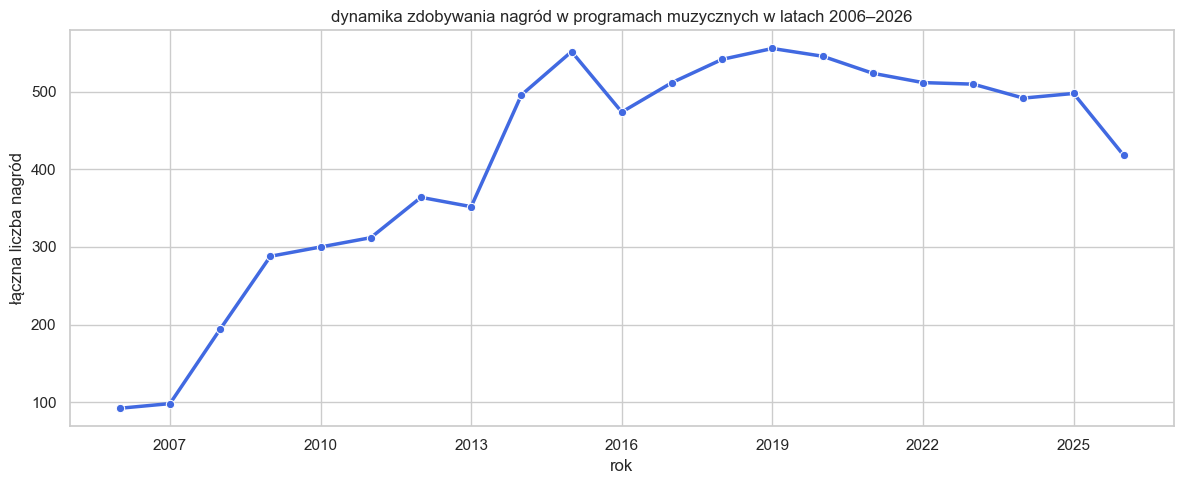

In [7]:
print("\nnajwięcej wygranych nagród")
top_artists_awards = df_awards['artist'].value_counts().head(10).reset_index()
top_artists_awards.columns = ['artist', 'award_count']

plt.figure(figsize=(12, 5))
sns.barplot(data=top_artists_awards, x='award_count', y='artist', palette="viridis", hue="artist", legend=False)
plt.title("top 10 artystów z największą liczbą nagród w programach muzycznych")
plt.xlabel("liczba wygranych nagród")
plt.ylabel("artysta")
plt.tight_layout()
plt.show()

print("rozkład nagród według stacji/programów muzycznych")
awards_by_show = df_awards['award_name'].value_counts().reset_index()
awards_by_show.columns = ['award_name', 'count']

plt.figure(figsize=(12, 5))
sns.barplot(data=awards_by_show, x='count', y='award_name', palette="magma", hue='award_name', legend=False)
plt.title("liczba nagród przyznawanych w poszczególnych programach muzycznych")
plt.xlabel("liczba nagród")
plt.ylabel("nazwa programu")
plt.tight_layout()
plt.show()

print("dynamika przyznawania nagród na przestrzeni lat")
df_awards['year'] = pd.to_numeric(df_awards['year'], errors='coerce')
df_awards = df_awards.dropna(subset=['year'])
df_awards['year'] = df_awards['year'].astype(int)

awards_by_year = (df_awards.groupby('year').size().reset_index(name='total_awards'))

plt.figure(figsize=(12, 5))
ax = sns.lineplot(data=awards_by_year, x='year', y='total_awards', marker='o', color='royalblue', linewidth=2.5,)

from matplotlib.ticker import MaxNLocator
ax.xaxis.set_major_locator(MaxNLocator(integer=True))

plt.title("dynamika zdobywania nagród w programach muzycznych w latach 2006–2026")
plt.xlabel("rok")
plt.ylabel("łączna liczba nagród")
plt.tight_layout()
plt.show()